In [ ]:
# Copy from https://github.com/cosmodesi/desilike/blob/main/nb/png_examples.ipynb 
import numpy as np
from matplotlib import pyplot as plt

from cosmoprimo.fiducial import DESI

cosmo = DESI()
edges = np.linspace(0., 0.3, 61)
k = (edges[:-1] + edges[1:]) / 2.
nmodes = 4. * np.pi / 3. * (edges[1:]**3 - edges[:-1]**3)
z = 1.
fo = cosmo.get_fourier()
pk = fo.pk_interpolator(of='delta_cb')(k, z=z)
pk_prim = cosmo.get_primordial(mode='scalar').pk_interpolator()(k)
pphi_prim = 9 / 25 * 2 * np.pi**2 / k**3 * pk_prim / cosmo.h**3
alpha = 1. / (pk / pphi_prim)**0.5

fnl = 100.
# PNG response of dark matter halos in spherical collapse
b1 = 2.
bphi = 2. * 1.686 * (b1 - 1.)
b = b1 + bphi * fnl * alpha
f = fo.sigma8_z(z, of='theta_cb') / fo.sigma8_z(z, of='delta_cb')
shotnoise = 1 / 1e-4
volume = 1e9

ells = (0, 2)
poles = []
poles.append((b**2 + 2. / 3. * f * b + 1. / 5. * f**2) * pk + shotnoise)
poles.append((4. / 3. * f * b + 4. / 7. * f**2) * pk)
poles = np.array(poles, dtype='f8')

from pypower import PowerSpectrumStatistics
mean = PowerSpectrumStatistics(edges, k, poles, nmodes=nmodes, ells=ells, shotnoise_nonorm=shotnoise, statistic='multipole')
cov = [2. * (2. * np.pi)**3 / (2 * ell + 1) / (volume * nmodes) * poles[0]**2 for ell in ells]
cov = np.diag(np.concatenate(cov, axis=0))

rng = np.random.RandomState(seed=42)
mocks = []
for i in range(1000):
    tmp = mean.deepcopy()
    tmp.power_nonorm.flat[...] = rng.multivariate_normal(mean.power_nonorm.ravel(), cov)
    mocks.append(tmp)
data, mocks = mocks[0], mocks[1:]

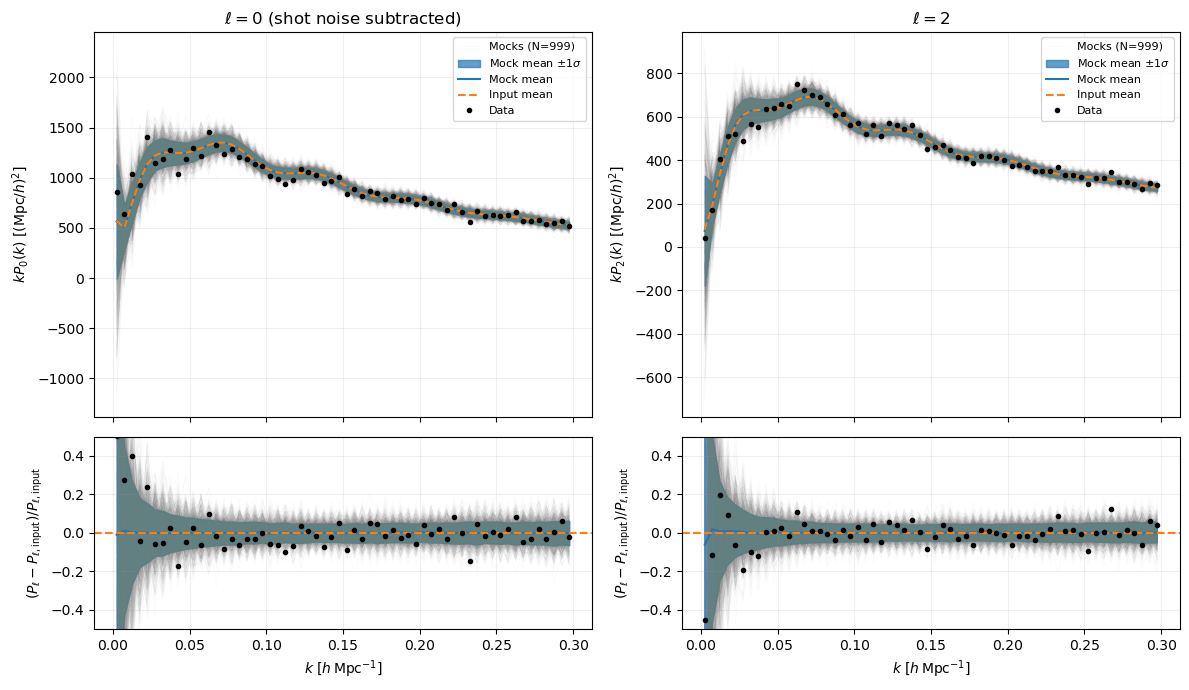

In [2]:
# Read normalized, shot-noise-subtracted spectra through the pypower API.
plot_k = data.k
plot_ells = data.ells
mock_power = np.array([mock.get_power(remove_shotnoise=True, complex=False) for mock in mocks])
data_power = data.get_power(remove_shotnoise=True, complex=False)
input_power = mean.get_power(remove_shotnoise=True, complex=False)
mock_mean = mock_power.mean(axis=0)
mock_std = mock_power.std(axis=0, ddof=1)

fig, axes = plt.subplots(2, len(plot_ells), figsize=(12, 7), sharex='col',
                         squeeze=False, gridspec_kw={'height_ratios': [3, 1.5]})
for i, (ell, ax) in enumerate(zip(plot_ells, axes[0])):
    lines = ax.plot(plot_k, (plot_k * mock_power[:, i, :]).T,
                    color='gray', alpha=0.04, lw=0.5, rasterized=True)
    lines[0].set_label(f'Mocks (N={len(mocks)})')
    ax.fill_between(plot_k, plot_k * (mock_mean[i] - mock_std[i]),
                    plot_k * (mock_mean[i] + mock_std[i]),
                    color='C0', alpha=0.7, label=r'Mock mean $\pm 1\sigma$')
    ax.plot(plot_k, plot_k * mock_mean[i], color='C0', lw=1.5, label='Mock mean')
    ax.plot(plot_k, plot_k * input_power[i], color='C1', ls='--', label='Input mean')
    ax.plot(plot_k, plot_k * data_power[i], 'o', color='k', ms=3, label='Data')
    ax.set_ylabel(rf'$k P_{{{ell}}}(k)\ [(\mathrm{{Mpc}}/h)^2]$')
    ax.set_title(rf'$\ell={ell}$' + (' (shot noise subtracted)' if ell == 0 else ''))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

    # Fractional residuals are undefined where the input mean is zero.
    reference = np.where(input_power[i] != 0., input_power[i], np.nan)
    relative_mocks = (mock_power[:, i, :] - input_power[i]) / reference
    relative_mean = (mock_mean[i] - input_power[i]) / reference
    relative_std = mock_std[i] / np.abs(reference)
    relative_data = (data_power[i] - input_power[i]) / reference
    residual_ax = axes[1, i]
    residual_ax.plot(plot_k, relative_mocks.T, color='gray', alpha=0.04,
                     lw=0.5, rasterized=True)
    residual_ax.fill_between(plot_k, relative_mean - relative_std,
                             relative_mean + relative_std, color='C0', alpha=0.7)
    residual_ax.plot(plot_k, relative_mean, color='C0', lw=1.5)
    residual_ax.axhline(0., color='C1', ls='--')
    residual_ax.plot(plot_k, relative_data, 'o', color='k', ms=3)
    residual_ax.set_xlabel(r'$k\ [h\,\mathrm{Mpc}^{-1}]$')
    residual_ax.set_ylabel(r'$(P_\ell-P_{\ell,\mathrm{input}})/P_{\ell,\mathrm{input}}$')
    residual_ax.grid(alpha=0.2)
    residual_ax.set_ylim(-0.5, 0.5)
fig.tight_layout()
plt.show()
